# 08 Vetting the new FMF detections (decision D21)

The final FMF catalog (aligned code, 10×MAD, no floor; decisions D20 and D23) holds the 28 reference events and the new detections counted below. Many new detections lie 4–15 s from a stronger detection, mostly 5–9 s after one. In a dense swarm such detections can be real small events. A template can also re-match a larger event's later phases at a fixed lag, an "alias".

This notebook gathers evidence on every new detection; it removes nothing, and which detections go on to relocation is your decision. It uses three independent checks:

**(a) Template windows, scaled to the detection.** Per-channel CC between each template window and the data. The data are the arrays the scan itself correlated: the same loader, the same grid alignment, the same samples. The signal-to-noise ratio of each window is measured against the 5 s before its arrival.
- Negative control: the same template at random times on 2025-11-01, a quiet day.
- Positive control: the 28 reference events, each evaluated with a *different* template.

**(b) Independent picks.** PhaseNet+ picks were made long before FMF, on every station-day. For each detection the template predicts the P and S arrival times at every station. The check counts how many of those predictions have a PhaseNet+ pick of the right phase within 0.25 s (P) or 0.30 s (S). The expected chance count comes from the same predictions shifted by ±7–17 s, which reflects the local pick density of the swarm.

**(c) Repeat-at-lag test.** An alias template re-detects *every* comparable larger event at the same lag. For each template, the check asks whether several of its hits fall at the same lag (±0.25 s) after different strong events, where strong means a reference event or a detection with CC ≥ 0.5. Real small events follow larger ones at scattered lags. In a clustered swarm the same lags also recur by chance inside bursts, so the control must keep the clustering. Each strong event is jittered by up to ±2 s, 20 times: this destroys any exact lag but keeps the bursts. (A uniform reshuffle over the whole swarm, tried first, removes the clustering and badly understates chance: mean 4.8 against 166 observed.)

In [1]:
import os, sys, glob, functools
import numpy as np, pandas as pd
import multiprocessing as mp, concurrent.futures as cf
DL = '/home/msseo/works/72.2025_Imsil_swarm/DL_detection'; FA = f'{DL}/fmf_aligned'
os.environ.update(FMF_RUN='imsil_5_20H_aligned_mad10', FMF_MAD_K='10', FMF_CC_FLOOR='0', FMF_BAND='5,20', FMF_STATION_LIST=f'{FA}/stations_imsil_5_20H.csv', FMF_SEQUENCES='imsil',
                  FMF_TEMPLATE_CSV='imsil_templates_ref25.csv', MAD_SEGMENTED='1', FMF_SNR_MIN='1.2', FMF_MAD_SUBSAMPLE='8', FMF_STEP='1',
                  FMF_WORKERS='16', FMF_GPU_BUDGET='12e9', HELVETICA_DIR='/home/msseo/Download/Helvetica')
sys.path.insert(0, FA)
import config as C, scan, similarity as S
C.CATALOG_CSV = f'{DL}/catalogs/fmf_final/imsil_fmf_catalog.csv'   # the final catalog (decisions D20, D23: aligned code, 10 x MAD, no floor)
# loader workers started fresh (forkserver): forked workers die on PAGO (see README); the computation is unchanged
scan.ProcessPoolExecutor = functools.partial(cf.ProcessPoolExecutor, mp_context=mp.get_context('forkserver'))
import importlib.util
spec = importlib.util.spec_from_file_location('plotstyle', f'{DL}/pipeline/plotstyle.py'); plotstyle = importlib.util.module_from_spec(spec); spec.loader.exec_module(plotstyle)
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from obspy import UTCDateTime
from IPython.display import display
sh = S.load_shelly(); ev = [str(e) for e in sh['event_id']]; cusp = list(sh['cuspid'].astype(int))
stations = [str(s) for s in sh['stations']]; prefixes = [str(p) for p in sh['channels']]
cat = pd.read_csv(C.CATALOG_CSV, parse_dates=['origin']).sort_values('origin').reset_index(drop=True)
hits = pd.concat([d for d in (pd.read_parquet(f) for f in sorted(glob.glob(f'{C.DETECT_DIR}/det_*.parquet'))) if len(d)], ignore_index=True)
hits['origin_utc'] = pd.to_datetime(hits.origin_utc); hits = hits[(hits.cc >= C.ABS_CC_FLOOR) & (hits.n_present >= C.MIN_PRESENT_STATIONS)].reset_index(drop=True)
picks = pd.concat([pd.read_csv(f'{DL}/models/phasenet_plus/detection_location/2025/picks/picks_2025.{d}.csv', parse_dates=['peak_time']) for d in (305, 306, 307)], ignore_index=True)
tsec = lambda x: pd.to_datetime(x).values.astype('datetime64[ns]').astype('int64') / 1e9
t_cat = tsec(cat.origin)
print(f'{len(cat)} detections ({int(cat.is_new.sum())} new); {len(hits)} gated hits; {len(picks)} PhaseNet+ picks on 2025-11-01..03')

235 detections (207 new); 3551 gated hits; 24075 PhaseNet+ picks on 2025-11-01..03


## Data: the scanned days, loaded exactly as the scan loaded them

In [2]:
DAYS = {}
for doy in (305, 306, 307):
    data, present, day0 = scan.load_day(stations, prefixes, 2025, doy); DAYS[doy] = (data, present, day0)
    print(f'2025 DOY {doy}: {int(present.sum())} of {len(stations)} stations present')
comps = [str(c) for c in sh['components']]
def windows(ti, origin):
    # per live channel of template ti: CC with the scanned data at the detection, and the window SNR against the 5 s before its arrival
    o = UTCDateTime(pd.Timestamp(origin).to_pydatetime()); data, present, day0 = DAYS[o.julday]; out = []
    for si, ph, ci, mo, n, tw, j in S.channels_of(sh, ti):
        if not present[si]: continue
        i0 = int(round((o + float(sh['ref_s'][ti]) - day0) * C.FS)) + mo
        if i0 - 600 < 0 or i0 + n > data.shape[-1]: continue
        d = data[si, ci, i0:i0 + n].astype(np.float64); nz = data[si, ci, i0 + 50 - 600:i0 + 50 - 100].astype(np.float64)
        if not np.any(d): continue
        a, b = tw - tw.mean(), d - d.mean(); den = np.sqrt((a ** 2).sum() * (b ** 2).sum()); cc = float((a * b).sum() / den) if den > 0 else np.nan
        snr = float(np.sqrt((b ** 2).mean()) / np.sqrt(((nz - nz.mean()) ** 2).mean())) if np.any(nz) else np.nan
        out.append(dict(station=stations[si], phase=ph, comp=comps[ci], cc=cc, snr=snr))
    return pd.DataFrame(out)
def summarize(w):
    return dict(n_ch=len(w), med_cc=w.cc.median(), n_cc05=int((w.cc >= 0.5).sum()), frac_snr2=float((w.snr >= 2).mean()), med_snr=w.snr.median())

2025 DOY 305: 22 of 22 stations present


2025 DOY 306: 22 of 22 stations present


2025 DOY 307: 22 of 22 stations present


## (a) Template windows: new detections against the two controls

/tmp/ipykernel_4178731/2488960152.py:16: RuntimeWarning: invalid value encountered in scalar divide
  snr = float(np.sqrt((b ** 2).mean()) / np.sqrt(((nz - nz.mean()) ** 2).mean())) if np.any(nz) else np.nan


,n_ch,med_cc,n_cc05,frac_snr2,med_snr
kind,,,,,
new,23.0,0.309,6.0,0.042,1.126
noise control (2025-11-01),23.0,-0.001,0.0,0.000,0.975
"reference, other template",43.0,0.295,14.5,0.730,3.213


noise-control 99th percentiles: channels with CC >= 0.5: 0.0; fraction of windows with SNR >= 2: 0.12


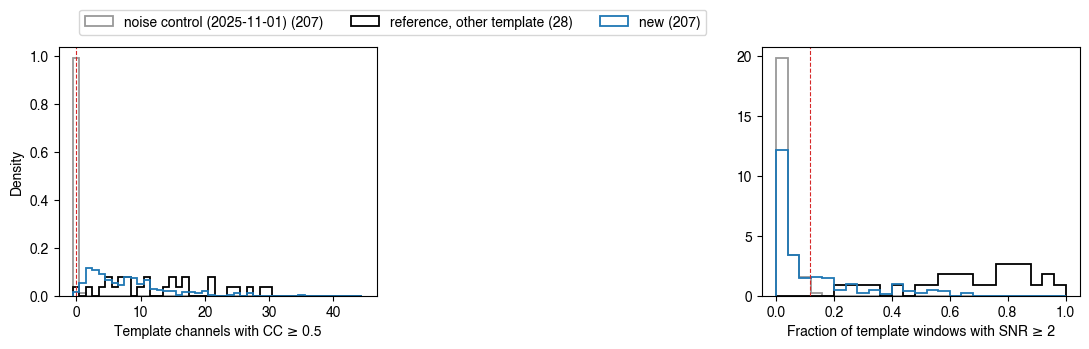

In [3]:
rng = np.random.default_rng(20261008)
new = cat[cat.is_new].copy(); A = []
for r in new.itertuples():
    A.append(dict(origin=r.origin, kind='new', **summarize(windows(cusp.index(int(r.template_cuspid)), r.origin))))
ref = cat[cat.is_reference]
for r in ref.itertuples():
    own = cat.reference_event_id.astype(str).loc[r.Index] if 'reference_event_id' in cat else ''
    k_own = ev.index(own) if own in ev else cusp.index(int(r.template_cuspid))
    k_other = (k_own + 7) % len(ev)                            # a different template, fixed offset in the template list
    A.append(dict(origin=r.origin, kind='reference, other template', **summarize(windows(k_other, r.origin))))
d305 = DAYS[305][2]
for r in new.itertuples():
    t = pd.Timestamp((d305 + float(rng.uniform(600, 86400 - 600))).datetime)
    A.append(dict(origin=t, kind='noise control (2025-11-01)', **summarize(windows(cusp.index(int(r.template_cuspid)), t))))
A = pd.DataFrame(A)
display(A.groupby('kind')[['n_ch', 'med_cc', 'n_cc05', 'frac_snr2', 'med_snr']].median().round(3))
noise = A[A.kind.str.startswith('noise')]
thr_cc05, thr_snr = noise.n_cc05.quantile(0.99), noise.frac_snr2.quantile(0.99)
print(f'noise-control 99th percentiles: channels with CC >= 0.5: {thr_cc05:.1f}; fraction of windows with SNR >= 2: {thr_snr:.2f}')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for kind, col in (('noise control (2025-11-01)', '0.6'), ('reference, other template', 'black'), ('new', 'tab:blue')):
    g = A[A.kind == kind]
    ax[0].hist(g.n_cc05, bins=np.arange(-0.5, 45.5, 1), histtype='step', lw=1.3, color=col, label=f'{kind} ({len(g)})', density=True)
    ax[1].hist(g.frac_snr2, bins=np.linspace(0, 1, 26), histtype='step', lw=1.3, color=col, density=True)
ax[0].axvline(thr_cc05, color='tab:red', lw=0.8, ls='--'); ax[1].axvline(thr_snr, color='tab:red', lw=0.8, ls='--')
ax[0].set_xlabel('Template channels with CC ≥ 0.5'); ax[1].set_xlabel('Fraction of template windows with SNR ≥ 2'); ax[0].set_ylabel('Density')
ax[0].legend(loc='lower center', bbox_to_anchor=(1.05, 1.02), ncol=3, frameon=True); plt.tight_layout(); plt.show()

## (b) Independent PhaseNet+ picks at the predicted arrivals

,n_pred,n_match,expected,excess
kind,,,,
new,14.0,2.0,0.0,2.0
reference,28.5,28.5,0.0,28.5


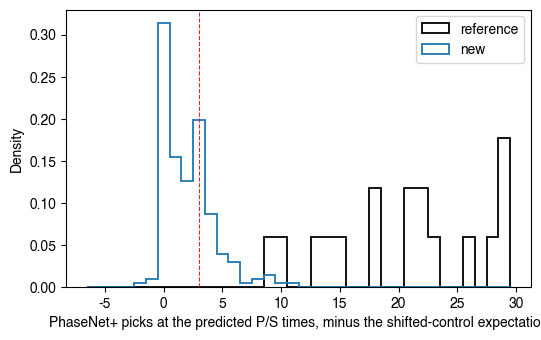

In [4]:
pk_t = {(s, ph): np.sort(tsec(g.peak_time)) for (s, ph), g in picks.groupby(['station', 'phase'])}
SHIFTS = [-17.3, -13.1, -9.7, -7.1, 7.3, 9.9, 13.7, 16.9]
def predicted(ti, origin):
    o = tsec([origin])[0]; out = {}
    for si, ph, ci, mo, n, tw, j in S.channels_of(sh, ti):
        out.setdefault((stations[si], ph), o + float(sh['ref_s'][ti]) + mo / C.FS + 0.5)
    return out
def matches(pred, shift=0.0):
    m = 0
    for (s, ph), t in pred.items():
        arr = pk_t.get((s, ph)); tol = 0.25 if ph == 'P' else 0.30
        if arr is None or not len(arr): continue
        i = np.searchsorted(arr, t + shift); m += int(any(abs(arr[k] - (t + shift)) <= tol for k in (i - 1, i) if 0 <= k < len(arr)))
    return m
B = []
for r in cat.itertuples():
    pred = predicted(cusp.index(int(r.template_cuspid)), r.origin)
    bg = np.mean([matches(pred, s) for s in SHIFTS])
    B.append(dict(origin=r.origin, kind='new' if r.is_new else 'reference', n_pred=len(pred), n_match=matches(pred), expected=bg))
B = pd.DataFrame(B); B['excess'] = B.n_match - B.expected
display(B.groupby('kind')[['n_pred', 'n_match', 'expected', 'excess']].median().round(2))
fig, ax = plt.subplots(figsize=(6, 3.6))
for kind, col in (('reference', 'black'), ('new', 'tab:blue')):
    ax.hist(B[B.kind == kind].excess, bins=np.arange(-6.5, 30.5, 1), histtype='step', lw=1.3, color=col, label=kind, density=True)
ax.axvline(3, color='tab:red', lw=0.8, ls='--'); ax.set_xlabel('PhaseNet+ picks at the predicted P/S times, minus the shifted-control expectation'); ax.set_ylabel('Density')
ax.legend(frameon=True); plt.show()

## (c) Repeat-at-lag test

80 strong events; hits with a repeated lag after >= 3 different strong events: observed 311; jittered (+-2 s) control: mean 320.8, 5-95 % 211-432; observed above the 95th percentile: False


lag_s,5.7,11.7,5.8,12.6,6.3,5.9,6.4,12.7,6.1,11.9
flagged hit-event pairs,39,31,30,27,23,23,21,17,15,12


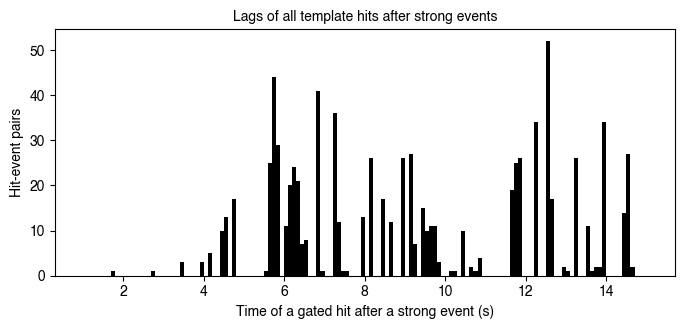

new detections whose representative hit carries the repeated-lag pattern: 24


In [5]:
strong_all = np.sort(np.r_[t_cat[cat.is_reference.values], t_cat[(cat.cc >= 0.5).values]])
strong_t = strong_all[np.r_[True, np.diff(strong_all) >= 2]]          # a reference event and its own detection are one strong event
def alias_hits(strong, tol=0.25, lo=4.0, hi=15.0, sep=2.0, return_lags=False):
    # hits of a template whose lag after a strong event is shared (within tol) by >= 2 other hits of the same template after other
    # strong events (hits and events all > sep apart): the repeat-at-lag signature
    flagged, rows = set(), []
    for k, g in hits.groupby('template_idx'):
        th = np.sort(tsec(g.origin_utc)); lags = [(h, e, h - e) for h in th for e in strong[(strong >= h - hi) & (strong <= h - lo)]]
        for h, e, L in lags:
            n = len({e2 for h2, e2, L2 in lags if abs(e2 - e) > sep and abs(h2 - h) > sep and abs(L2 - L) <= tol})
            if n >= 2: flagged.add((k, round(h, 2))); rows.append(dict(template=cusp[k], lag_s=round(L, 1)))
    return (flagged, pd.DataFrame(rows)) if return_lags else flagged
obs, lagtab = alias_hits(strong_t, return_lags=True)
shuf = [len(alias_hits(np.sort(strong_t + rng.uniform(-2, 2, len(strong_t))))) for _ in range(20)]   # jitter control: keeps the clustering
excess_c = len(obs) > np.percentile(shuf, 95)
print(f'{len(strong_t)} strong events; hits with a repeated lag after >= 3 different strong events: observed {len(obs)}; '
      f'jittered (+-2 s) control: mean {np.mean(shuf):.1f}, 5-95 % {np.percentile(shuf, 5):.0f}-{np.percentile(shuf, 95):.0f}; observed above the 95th percentile: {excess_c}')
display(lagtab.groupby('lag_s').size().sort_values(ascending=False).head(10).rename('flagged hit-event pairs').to_frame().T)
allag = np.concatenate([tsec(g.origin_utc)[:, None] - strong_t[None, :] for _, g in hits.groupby('template_idx')], axis=0).ravel()
allag = allag[(allag >= 1) & (allag <= 15)]
fig, ax = plt.subplots(figsize=(8, 3.2)); ax.hist(allag, bins=np.arange(1, 15.01, 0.1), color='black')
ax.set_xlabel('Time of a gated hit after a strong event (s)'); ax.set_ylabel('Hit-event pairs'); ax.set_title('Lags of all template hits after strong events', fontsize=10); plt.show()
cat['alias_pattern'] = [(cusp.index(int(r.template_cuspid)), round(t, 2)) in obs for r, t in zip(cat.itertuples(), t_cat)]
print('new detections whose representative hit carries the repeated-lag pattern:', int((cat.alias_pattern & cat.is_new).sum()))

## Per-detection evidence table
For each new detection the table lists:
- the time to the nearest stronger detection;
- the results of (a) and (b) against their controls;
- the repeat-at-lag flag (c).

"Pass (a)" means more channels with CC ≥ 0.5 than 99 % of the noise controls. "Pass (b)" means at least 3 PhaseNet+ picks above the shifted-control expectation.

,n,pass_a,pass_b,pass_both,alias_pattern
near_stronger,,,,,
isolated (no stronger detection within 15 s),114,113,58,58,2
within 15 s of a stronger detection,93,91,18,18,22


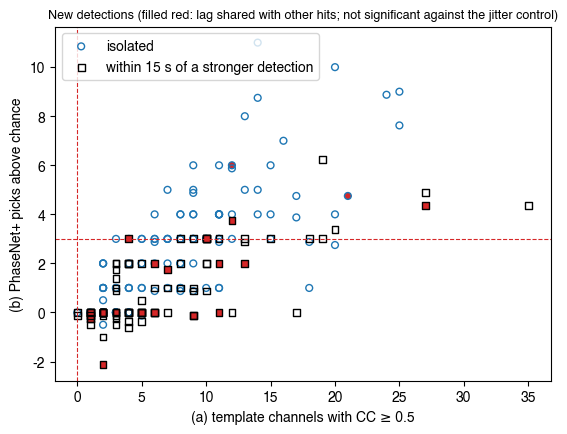

In [6]:
nn = cat[cat.is_new].reset_index(drop=True)
dt_strong = []
for i, r in nn.iterrows():
    t = tsec([r.origin])[0]; m = (np.abs(t_cat - t) <= 15) & (np.abs(t_cat - t) > 0.01) & (cat.is_reference.values | (cat.cc.values > r.cc))
    dt_strong.append((t_cat[m] - t)[np.argmin(np.abs(t_cat[m] - t))] if m.any() else np.nan)
nn['dt_to_stronger_s'] = dt_strong
vet = nn[['origin', 'template_cuspid', 'cc', 'n_present', 'dt_to_stronger_s', 'alias_pattern']].merge(
    A[A.kind == 'new'][['origin', 'n_cc05', 'frac_snr2', 'med_cc']], on='origin').merge(B[B.kind == 'new'][['origin', 'n_match', 'expected', 'excess']], on='origin')
vet['pass_a'] = vet.n_cc05 > thr_cc05; vet['pass_b'] = vet.excess >= 3
vet['near_stronger'] = vet.dt_to_stronger_s.abs() <= 15
vet.to_csv(f'{DL}/catalogs/fmf_new_detections_vetting.csv', index=False)
tab = vet.groupby('near_stronger').agg(n=('origin', 'size'), pass_a=('pass_a', 'sum'), pass_b=('pass_b', 'sum'), pass_both=('pass_a', lambda v: int((v & vet.loc[v.index, 'pass_b']).sum())),
                                       alias_pattern=('alias_pattern', 'sum'))
display(tab.rename(index={False: 'isolated (no stronger detection within 15 s)', True: 'within 15 s of a stronger detection'}))
fig, ax = plt.subplots(figsize=(6.4, 4.6))
for near, mk in ((False, 'o'), (True, 's')):
    g = vet[vet.near_stronger == near]
    ax.scatter(g.n_cc05, g.excess, marker=mk, s=24, facecolor=np.where(g.alias_pattern, 'tab:red', 'none'), edgecolor='tab:blue' if not near else 'black',
               label='isolated' if not near else 'within 15 s of a stronger detection')
ax.axvline(thr_cc05, color='tab:red', lw=0.8, ls='--'); ax.axhline(3, color='tab:red', lw=0.8, ls='--')
ax.set_xlabel('(a) template channels with CC ≥ 0.5'); ax.set_ylabel('(b) PhaseNet+ picks above chance'); ax.set_title('New detections (filled red: lag shared with other hits; not significant against the jitter control)', fontsize=9)
ax.legend(loc='upper left', frameon=True); plt.show()

## Waveforms of the detections next to a stronger event
These panels follow Haenam's near-event figure (notebook 46, W04; `section_panels.py`, copied). Each panel shows the vertical records at the four stations nearest the template event. Every trace is scaled inside the detection's **own** predicted P–S window and clipped at 1.5×, so a small detection beside a larger event stays visible. Each panel marks:
- the detection's predicted P and S (blue);
- the stronger event's P and S (red; picks for a reference event, predictions for a stronger detection);
- every raw PhaseNet+ pick (black: P, open: S).

The first figure shows the near-stronger detections that pass check (b), closest to their stronger event first. The second shows those that fail it.

/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds in conversion.
  dp = m[(m.kind == 'detection')]; tp_ = [(UTCDateTime(t.to_pydatetime()) - det) for t in dp.time]
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:48: UserWarning: Discarding nonzero nanoseconds in conversion.
  tq = UTCDateTime(q.time.to_pydatetime()) - det
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds in conversion.
  dp = m[(m.kind == 'detection')]; tp_ = [(UTCDateTime(t.to_pydatetime()) - det) for t in dp.time]
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:48: UserWarning: Discarding nonzero nanoseconds in conversion.
  tq = UTCDateTime(q.time.to_pydatetime()) - det
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds

/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds in conversion.
  dp = m[(m.kind == 'detection')]; tp_ = [(UTCDateTime(t.to_pydatetime()) - det) for t in dp.time]
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:48: UserWarning: Discarding nonzero nanoseconds in conversion.
  tq = UTCDateTime(q.time.to_pydatetime()) - det
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds in conversion.
  dp = m[(m.kind == 'detection')]; tp_ = [(UTCDateTime(t.to_pydatetime()) - det) for t in dp.time]
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:48: UserWarning: Discarding nonzero nanoseconds in conversion.
  tq = UTCDateTime(q.time.to_pydatetime()) - det
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds

N1: 8 near-stronger detections that pass (b)


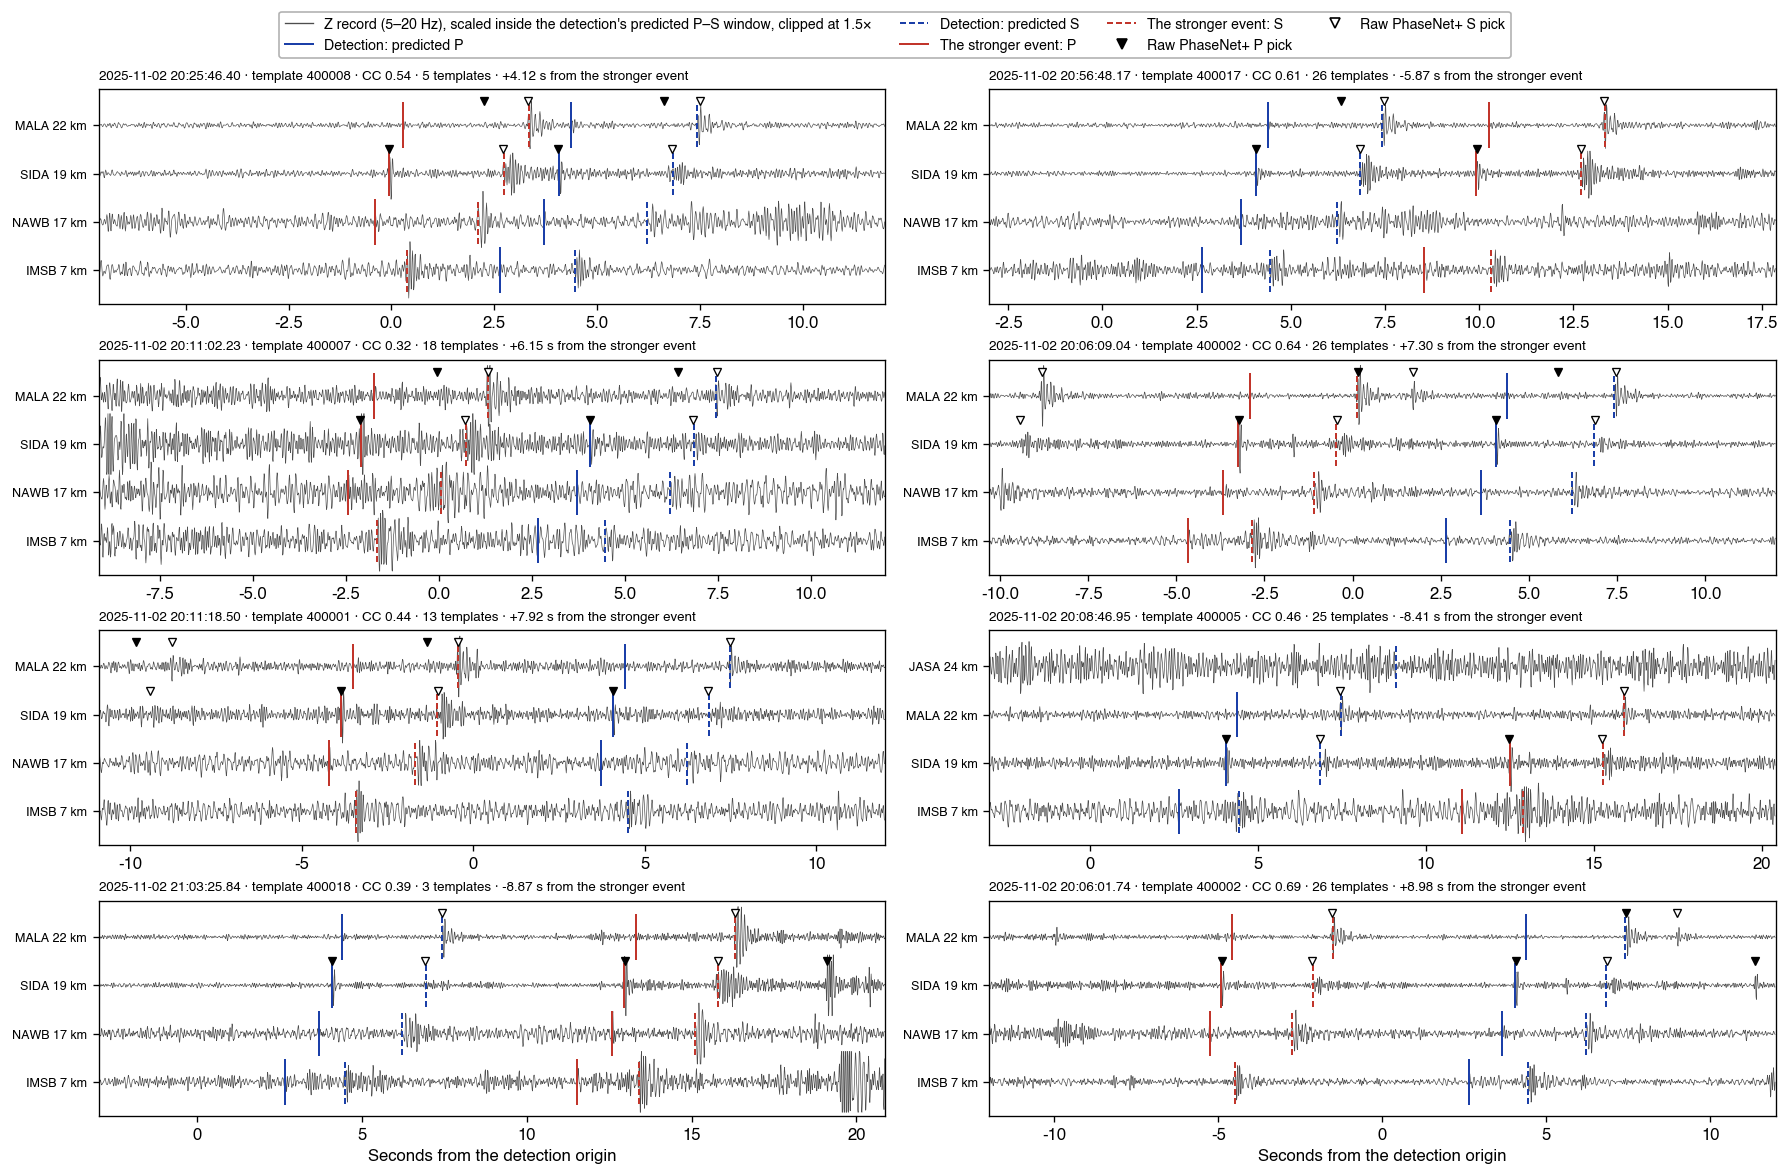

/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds in conversion.
  dp = m[(m.kind == 'detection')]; tp_ = [(UTCDateTime(t.to_pydatetime()) - det) for t in dp.time]
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:48: UserWarning: Discarding nonzero nanoseconds in conversion.
  tq = UTCDateTime(q.time.to_pydatetime()) - det
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds in conversion.
  dp = m[(m.kind == 'detection')]; tp_ = [(UTCDateTime(t.to_pydatetime()) - det) for t in dp.time]
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:48: UserWarning: Discarding nonzero nanoseconds in conversion.
  tq = UTCDateTime(q.time.to_pydatetime()) - det
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds

/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds in conversion.
  dp = m[(m.kind == 'detection')]; tp_ = [(UTCDateTime(t.to_pydatetime()) - det) for t in dp.time]
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:48: UserWarning: Discarding nonzero nanoseconds in conversion.
  tq = UTCDateTime(q.time.to_pydatetime()) - det
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds in conversion.
  dp = m[(m.kind == 'detection')]; tp_ = [(UTCDateTime(t.to_pydatetime()) - det) for t in dp.time]
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:48: UserWarning: Discarding nonzero nanoseconds in conversion.
  tq = UTCDateTime(q.time.to_pydatetime()) - det
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds

/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:43: UserWarning: Discarding nonzero nanoseconds in conversion.
  dp = m[(m.kind == 'detection')]; tp_ = [(UTCDateTime(t.to_pydatetime()) - det) for t in dp.time]
/home/msseo/works/72.2025_Imsil_swarm/DL_detection/fmf_aligned/section_panels.py:48: UserWarning: Discarding nonzero nanoseconds in conversion.
  tq = UTCDateTime(q.time.to_pydatetime()) - det


N2: 8 near-stronger detections that fail (b)


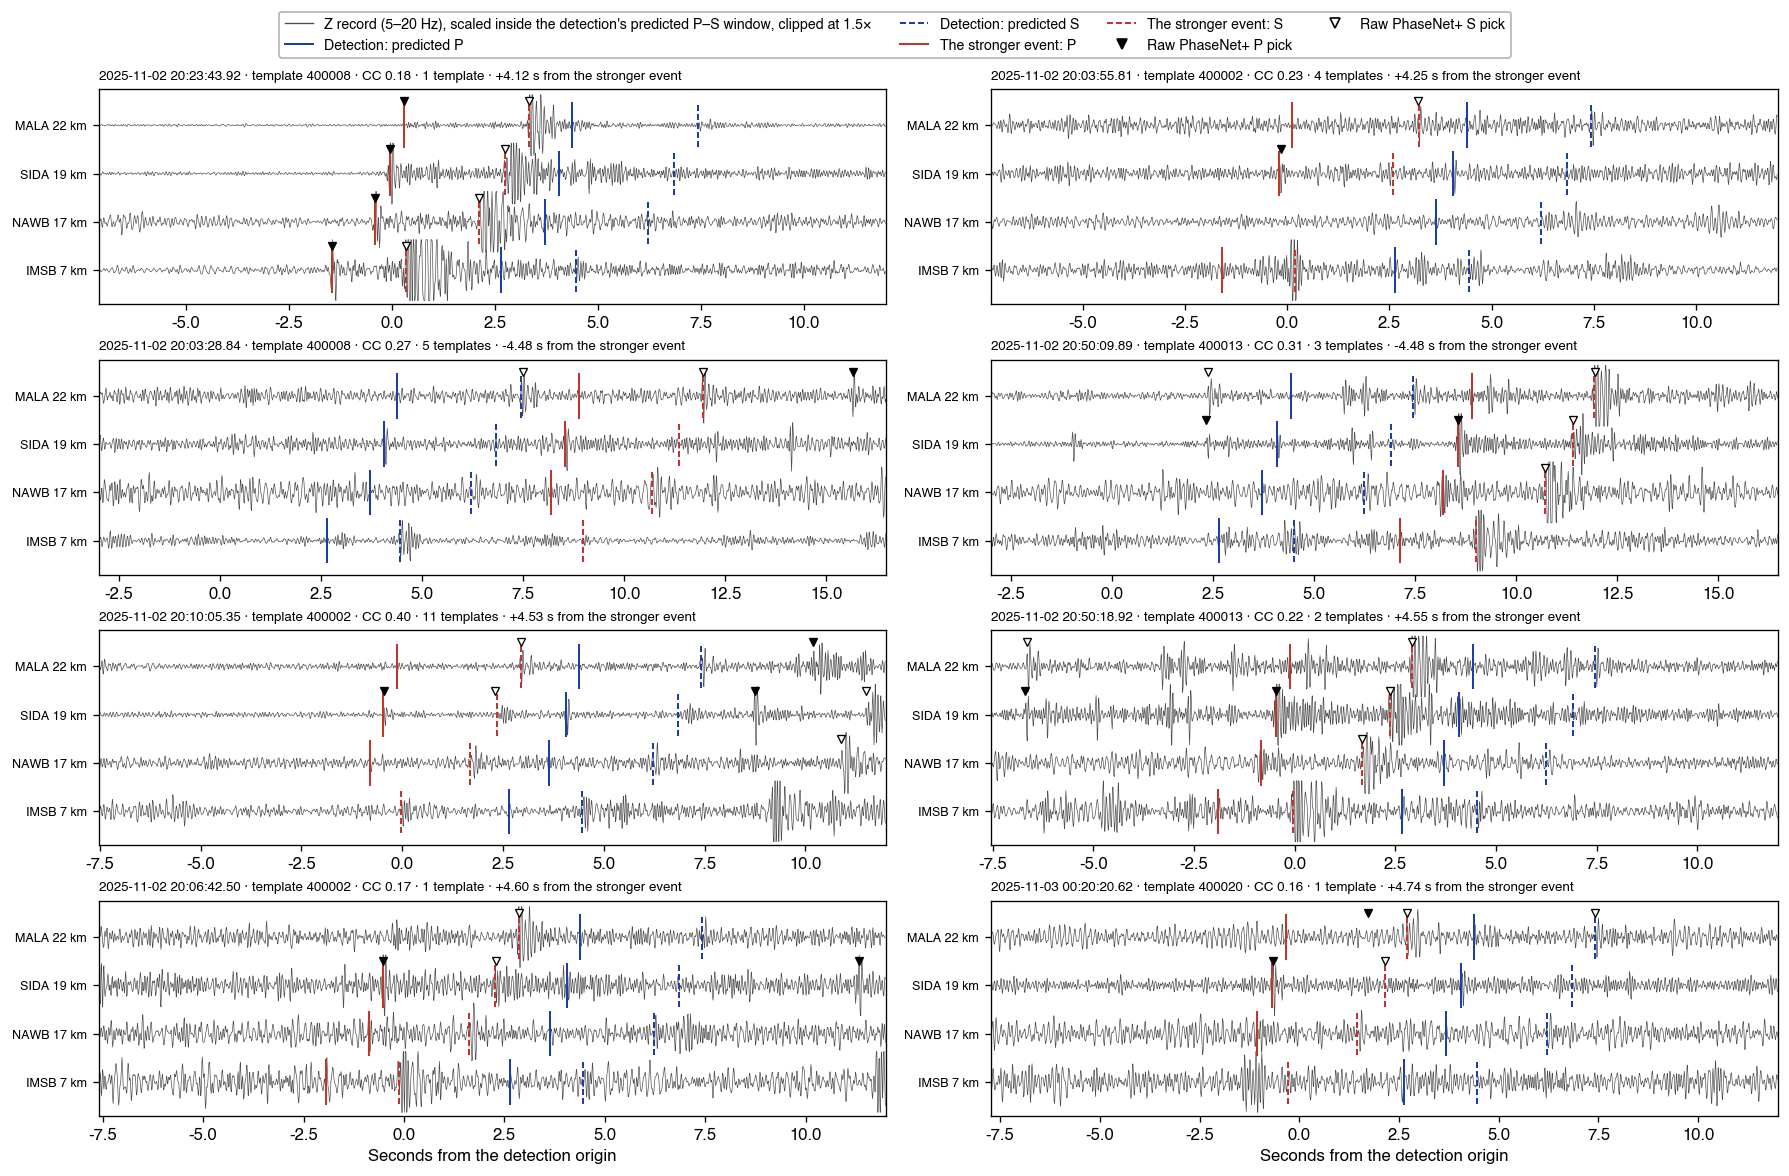

In [7]:
import section_panels as SP
sta_tab = pd.read_csv(f'{DL}/station_table/stations.csv'); sensor = {f'{r.Network}.{r.Code}': r.Sensor for r in sta_tab.itertuples()}
coords = {f'{r.Network}.{r.Code}': (r.Latitude, r.Longitude) for r in sta_tab.itertuples()}
tpl_loc = pd.read_csv(f'{DL}/catalogs/imsil_templates_ref25.csv').set_index('cuspid')
def km(a, b): return float(np.hypot((a[0] - b[0]) * 111.19, (a[1] - b[1]) * 111.19 * np.cos(np.radians(a[0]))))
def panel_rows(sel, fig_id, nsta=4):
    rows, marks = [], []
    for n, r in enumerate(sel.itertuples()):
        t = tsec([r.origin])[0]; m = (np.abs(t_cat - t) > 0.01) & (np.abs(t_cat - t) <= 15) & (cat.is_reference.values | (cat.cc.values > r.cc))
        j = np.where(m)[0][np.argmin(np.abs(t_cat[m] - t))]; E = cat.iloc[j]
        kD = cusp.index(int(r.template_cuspid)); predD = predicted(kD, r.origin)
        if E.is_reference and str(E.reference_event_id) in ev:
            kE = ev.index(str(E.reference_event_id)); predE = predicted(kE, pd.Timestamp(str(sh['origin_utc'][kE]))); lab = 'stronger event'
        else:
            kE = cusp.index(int(E.template_cuspid)); predE = predicted(kE, E.origin); lab = 'stronger event'
        loc = tuple(tpl_loc.loc[int(r.template_cuspid), ['latitude', 'longitude']])
        near = sorted({s for s, ph in predD}, key=lambda s: km(loc, coords[s]))[:nsta]
        t0 = pd.Timestamp(min(r.origin, E.origin)) - pd.Timedelta(seconds=3); t1 = pd.Timestamp(max(r.origin, E.origin)) + pd.Timedelta(seconds=12)
        rows.append(dict(figure=fig_id, row=n, detection=pd.Timestamp(r.origin), t0=t0, t1=t1, stations=';'.join(f'{s}:{km(loc, coords[s]):.1f}' for s in near),
                         template=int(r.template_cuspid), cc=r.cc, n_templates=int(cat.n_templates.iloc[(cat.origin - r.origin).abs().idxmin()]), other_time=pd.Timestamp(E.origin), other_label=lab))
        for kind, pred in (('detection', predD), ('other', predE)):
            for (s, ph), tt in pred.items():
                if s in near: marks.append(dict(row=n, station=s, kind=kind, phase=ph, time=pd.Timestamp(tt, unit='s')))
        pk = picks[picks.station.isin(near) & picks.peak_time.between(t0, t1)]
        marks += [dict(row=n, station=q.station, kind='raw', phase=q.phase, time=q.peak_time) for q in pk.itertuples()]
    return pd.DataFrame(rows), pd.DataFrame(marks)
FIG = f'{DL}/notebooks/figs_08'; os.makedirs(FIG, exist_ok=True)
from IPython.display import Image
for fig_id, sel, lab in (('N1', vet[vet.near_stronger & vet.pass_b], 'pass (b)'), ('N2', vet[vet.near_stronger & ~vet.pass_b], 'fail (b)')):
    sel = sel.reindex(sel.dt_to_stronger_s.abs().sort_values().index).head(8)
    rows, marks = panel_rows(sel, fig_id)
    png = SP.section_panels(fig_id, rows, marks, stations, prefixes, sensor, f'{FIG}/{fig_id}_near_stronger_{lab.replace(" ", "_").replace("(", "").replace(")", "")}.png', nsta=4)
    print(f'{fig_id}: {len(sel)} near-stronger detections that {lab}'); display(Image(png))

## Detection sets
These are Haenam's per-detection views (`similarity.plot_detection_set`), as in notebook 07:
- every live channel of the template as a row, ordered by distance;
- the record (gray) with the template's P (red) and S (blue) windows in place and their correlations;
- the detector's view: the template's network CC over the day and ±12 s around the detection.

Four detections are shown:
- the strongest isolated detection that fails (b);
- the weakest isolated detection that passes (a) and (b);
- the near-stronger detections that fail (b) closest to and farthest from their stronger event.

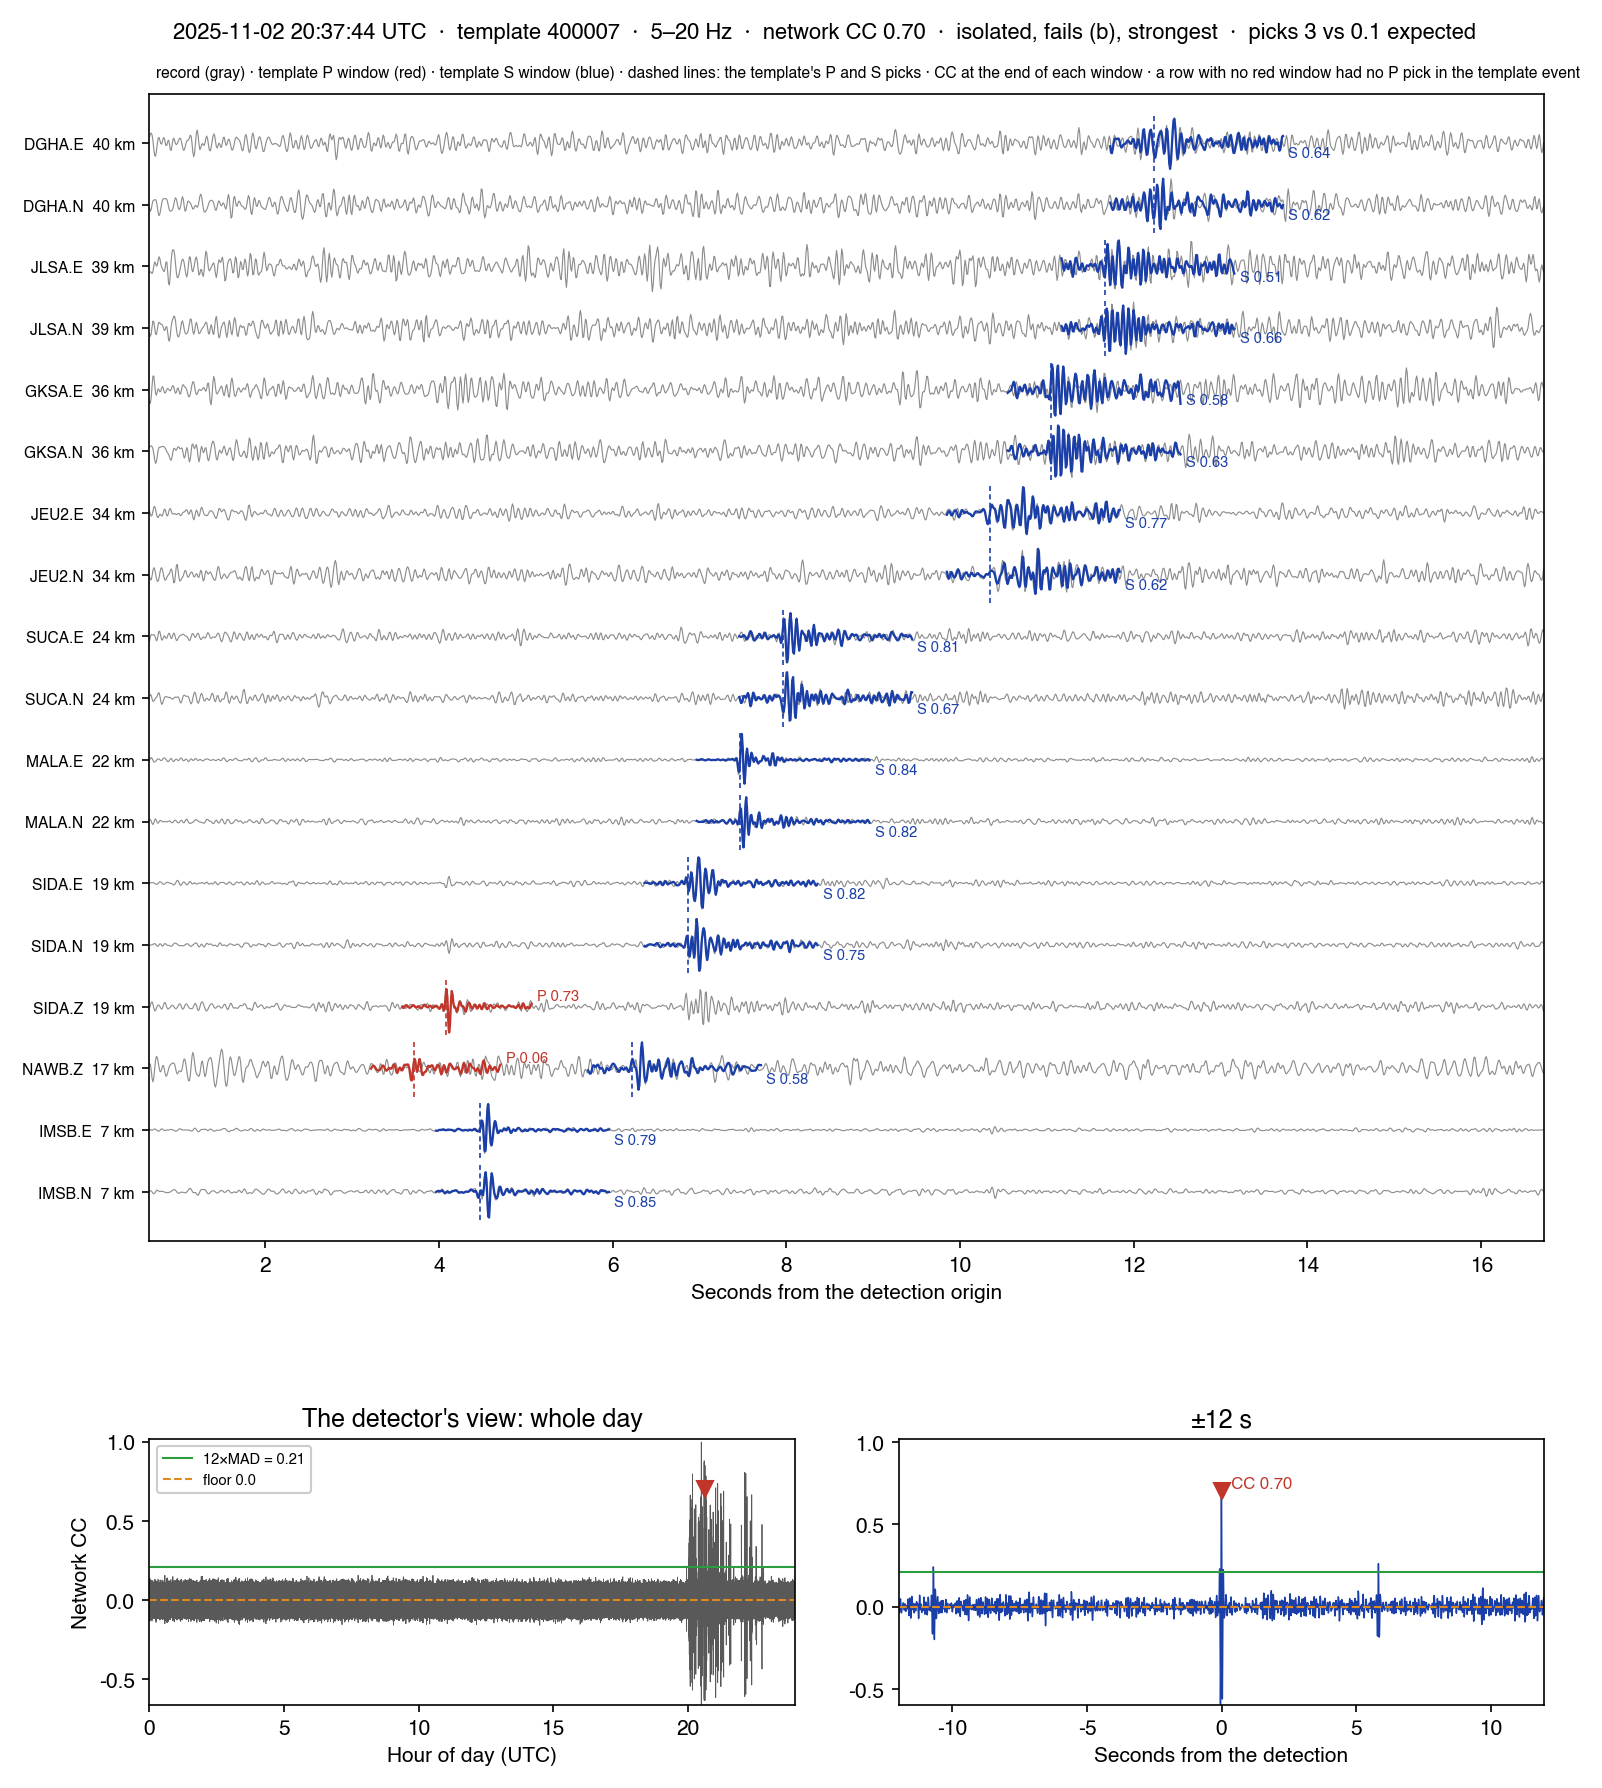

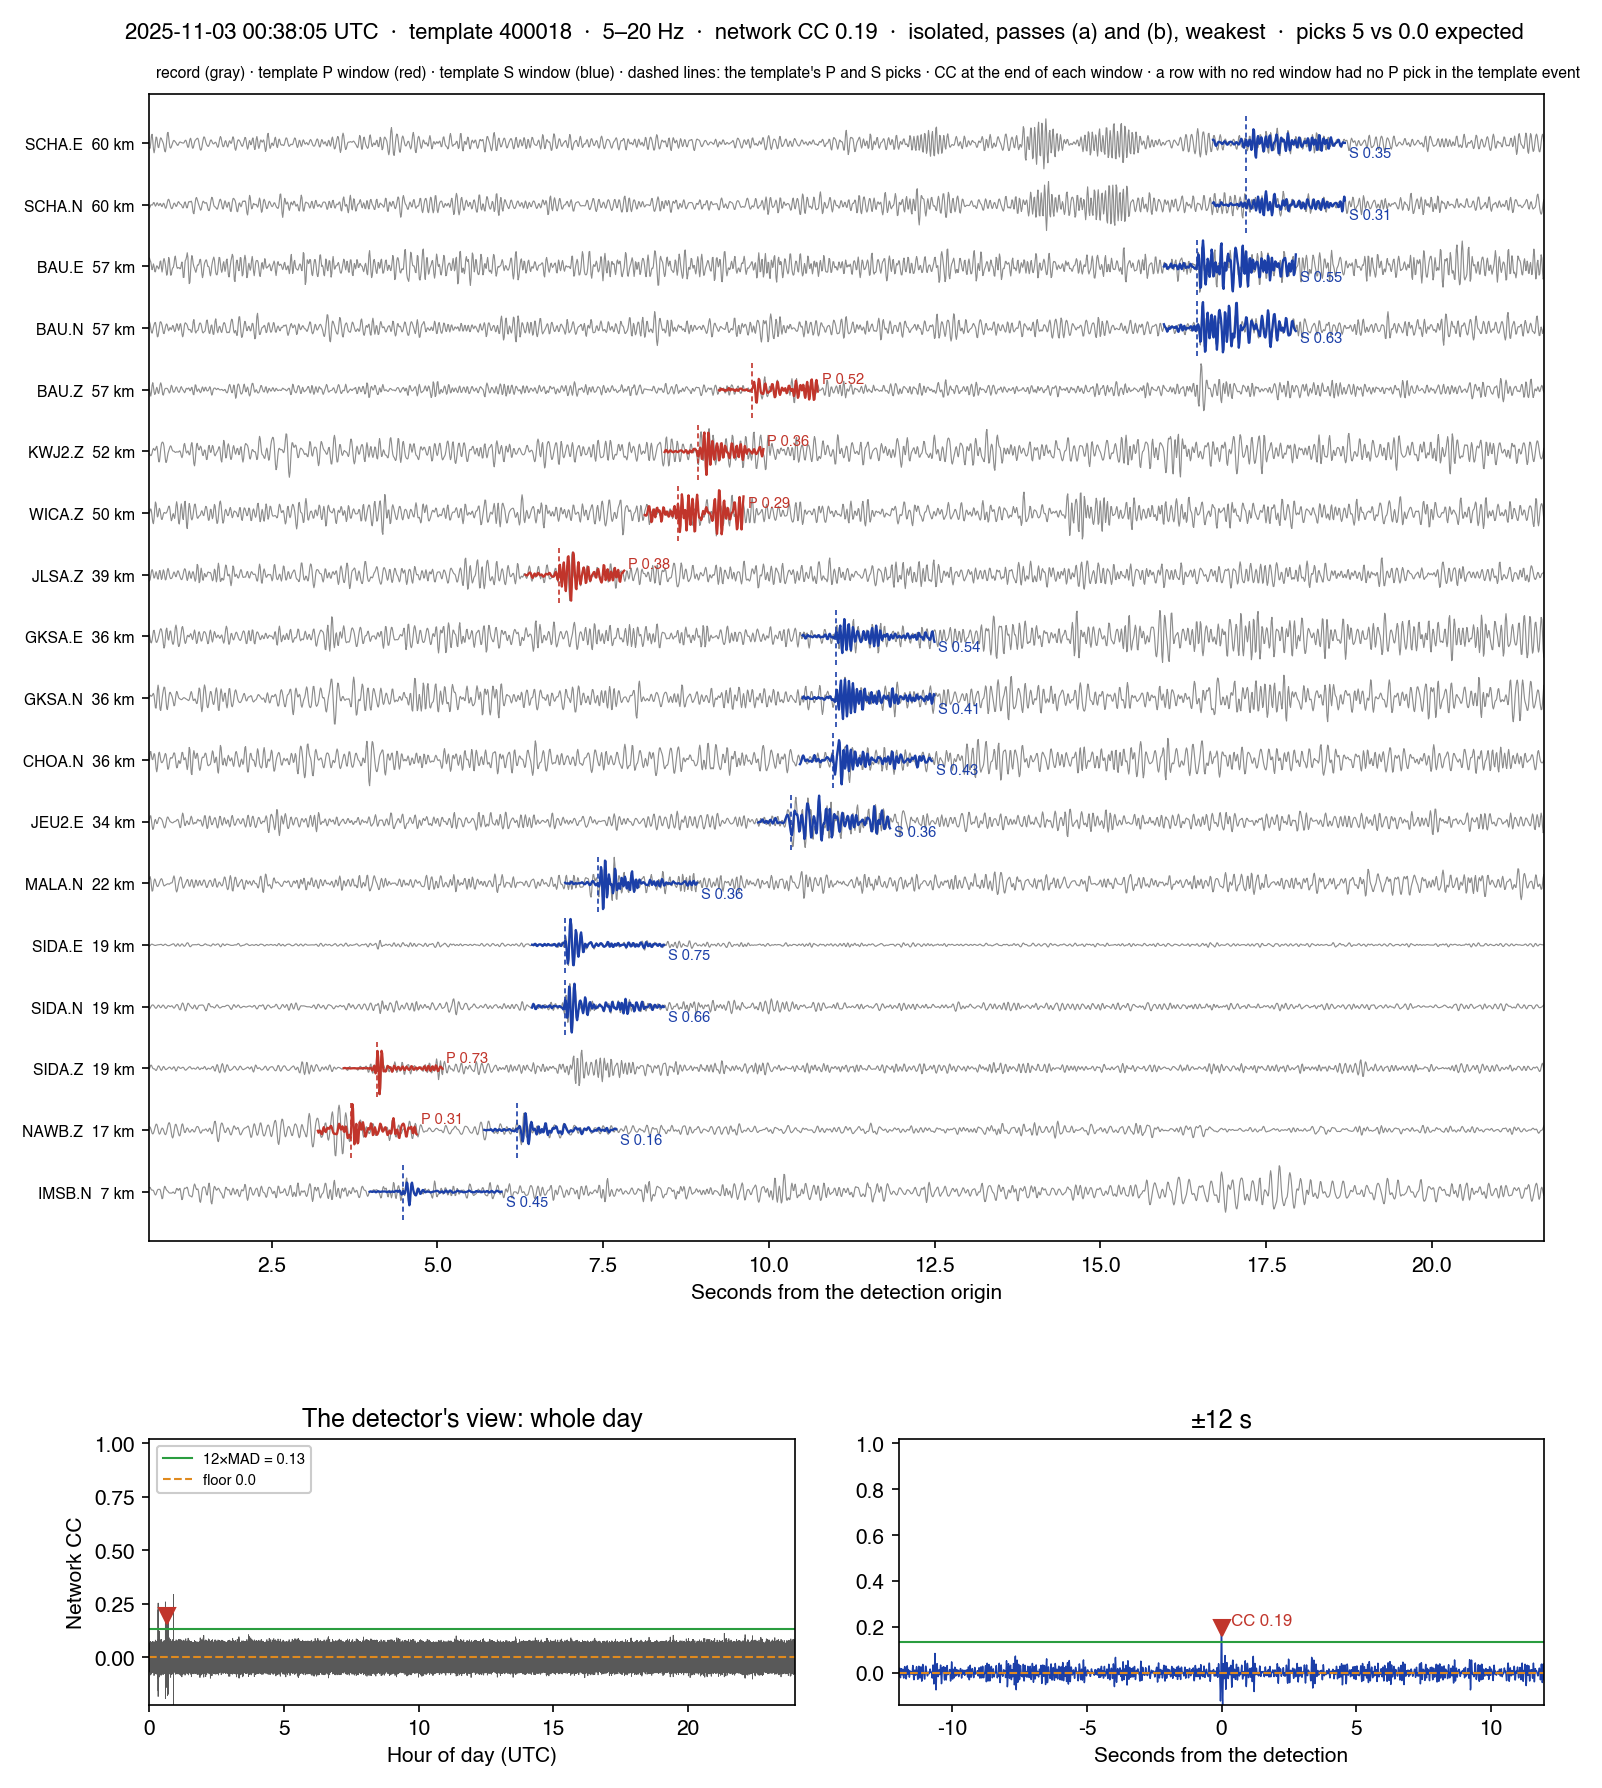

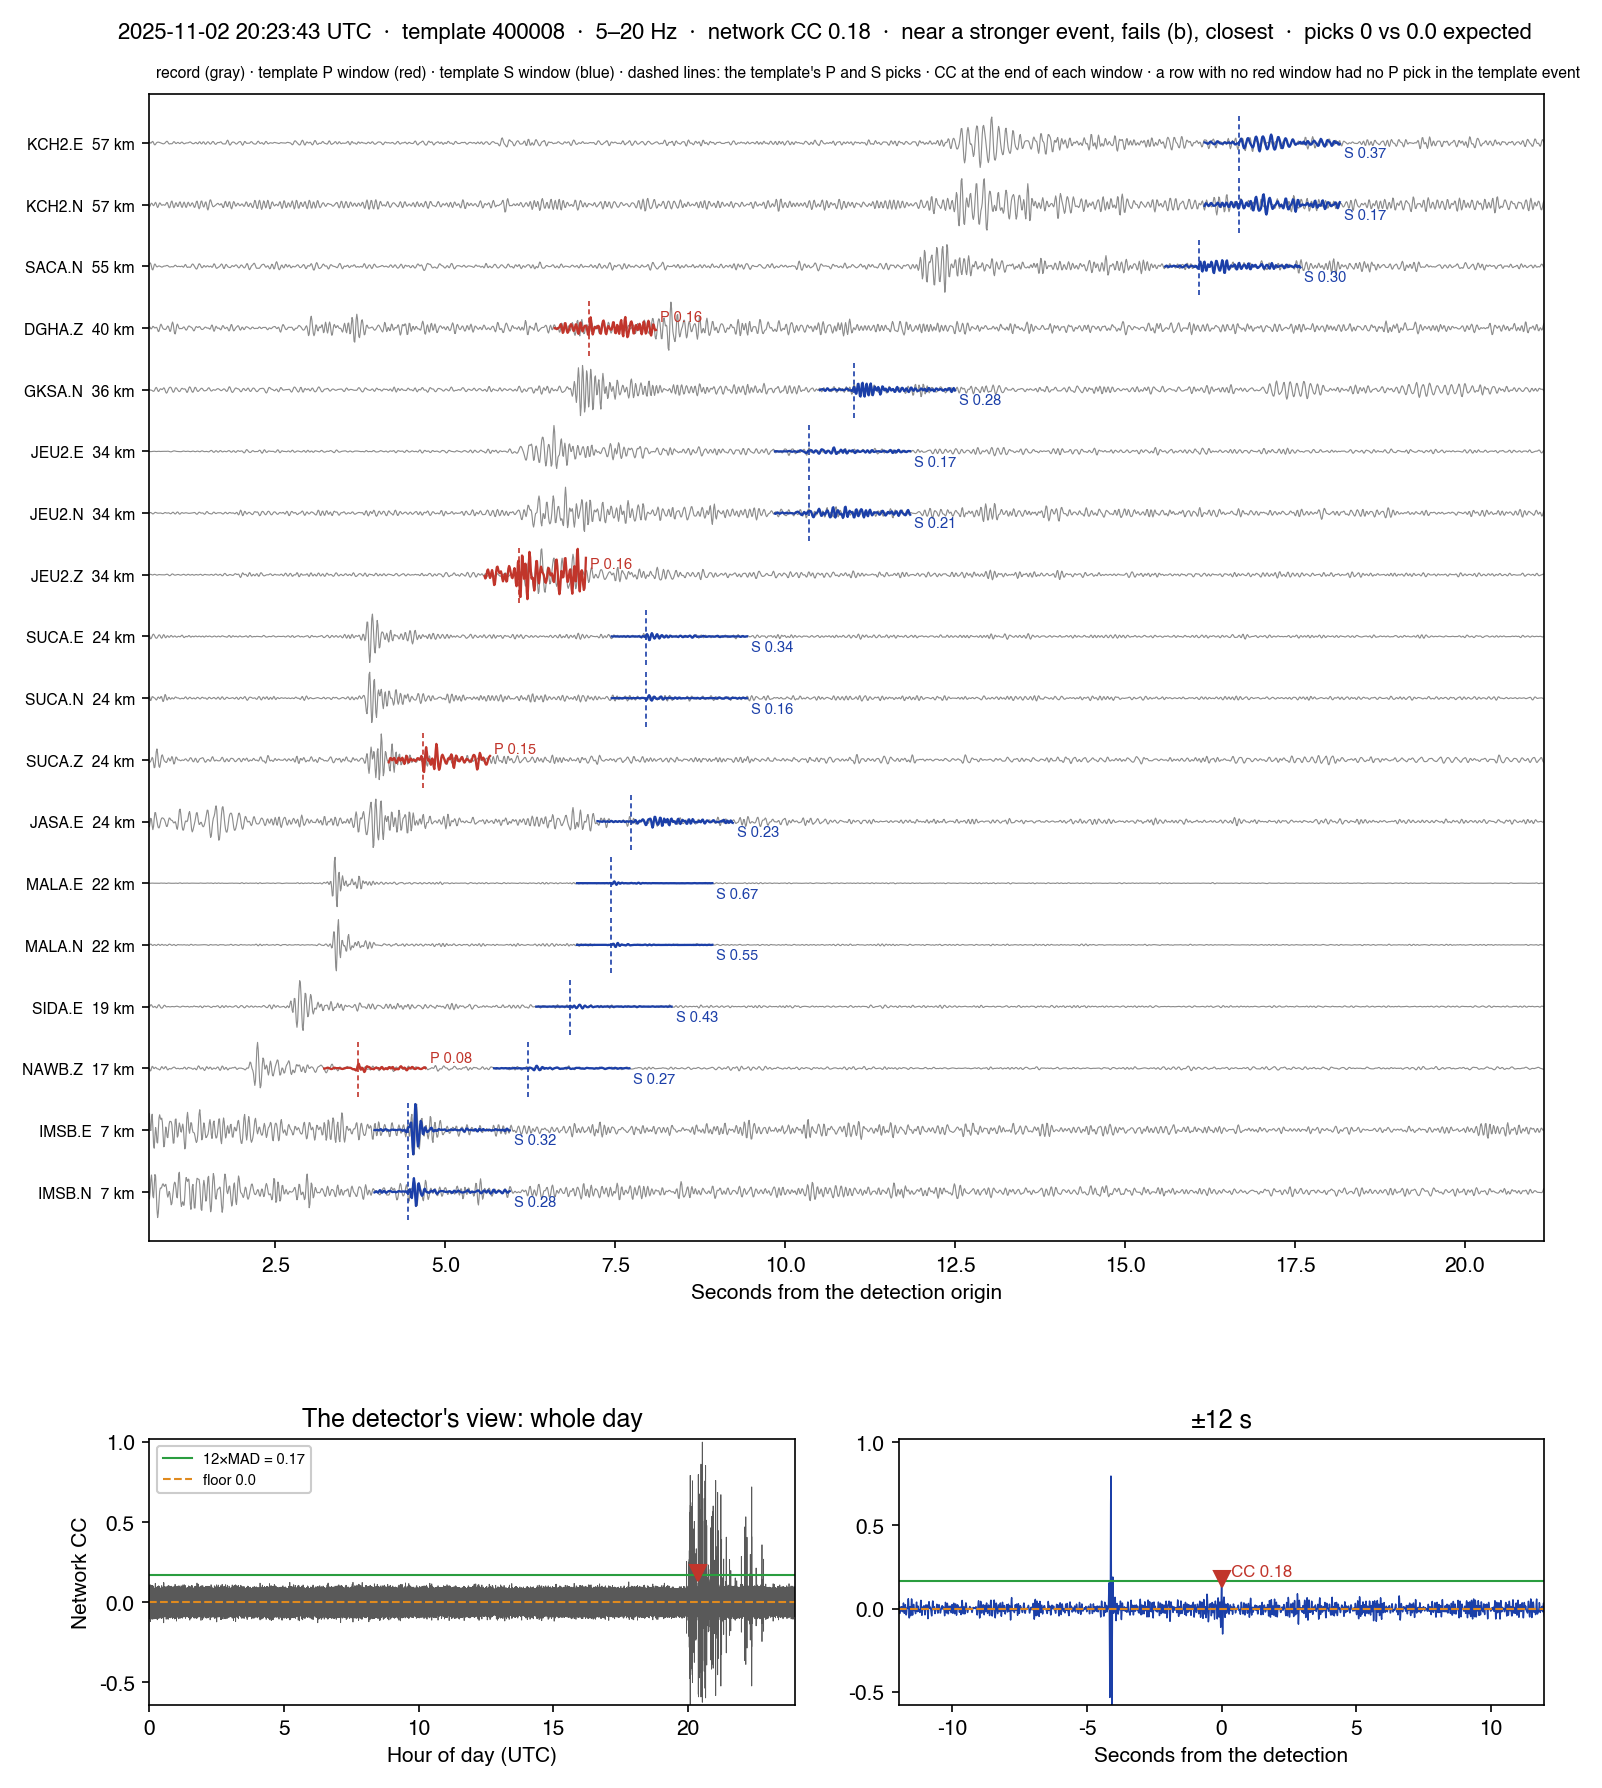

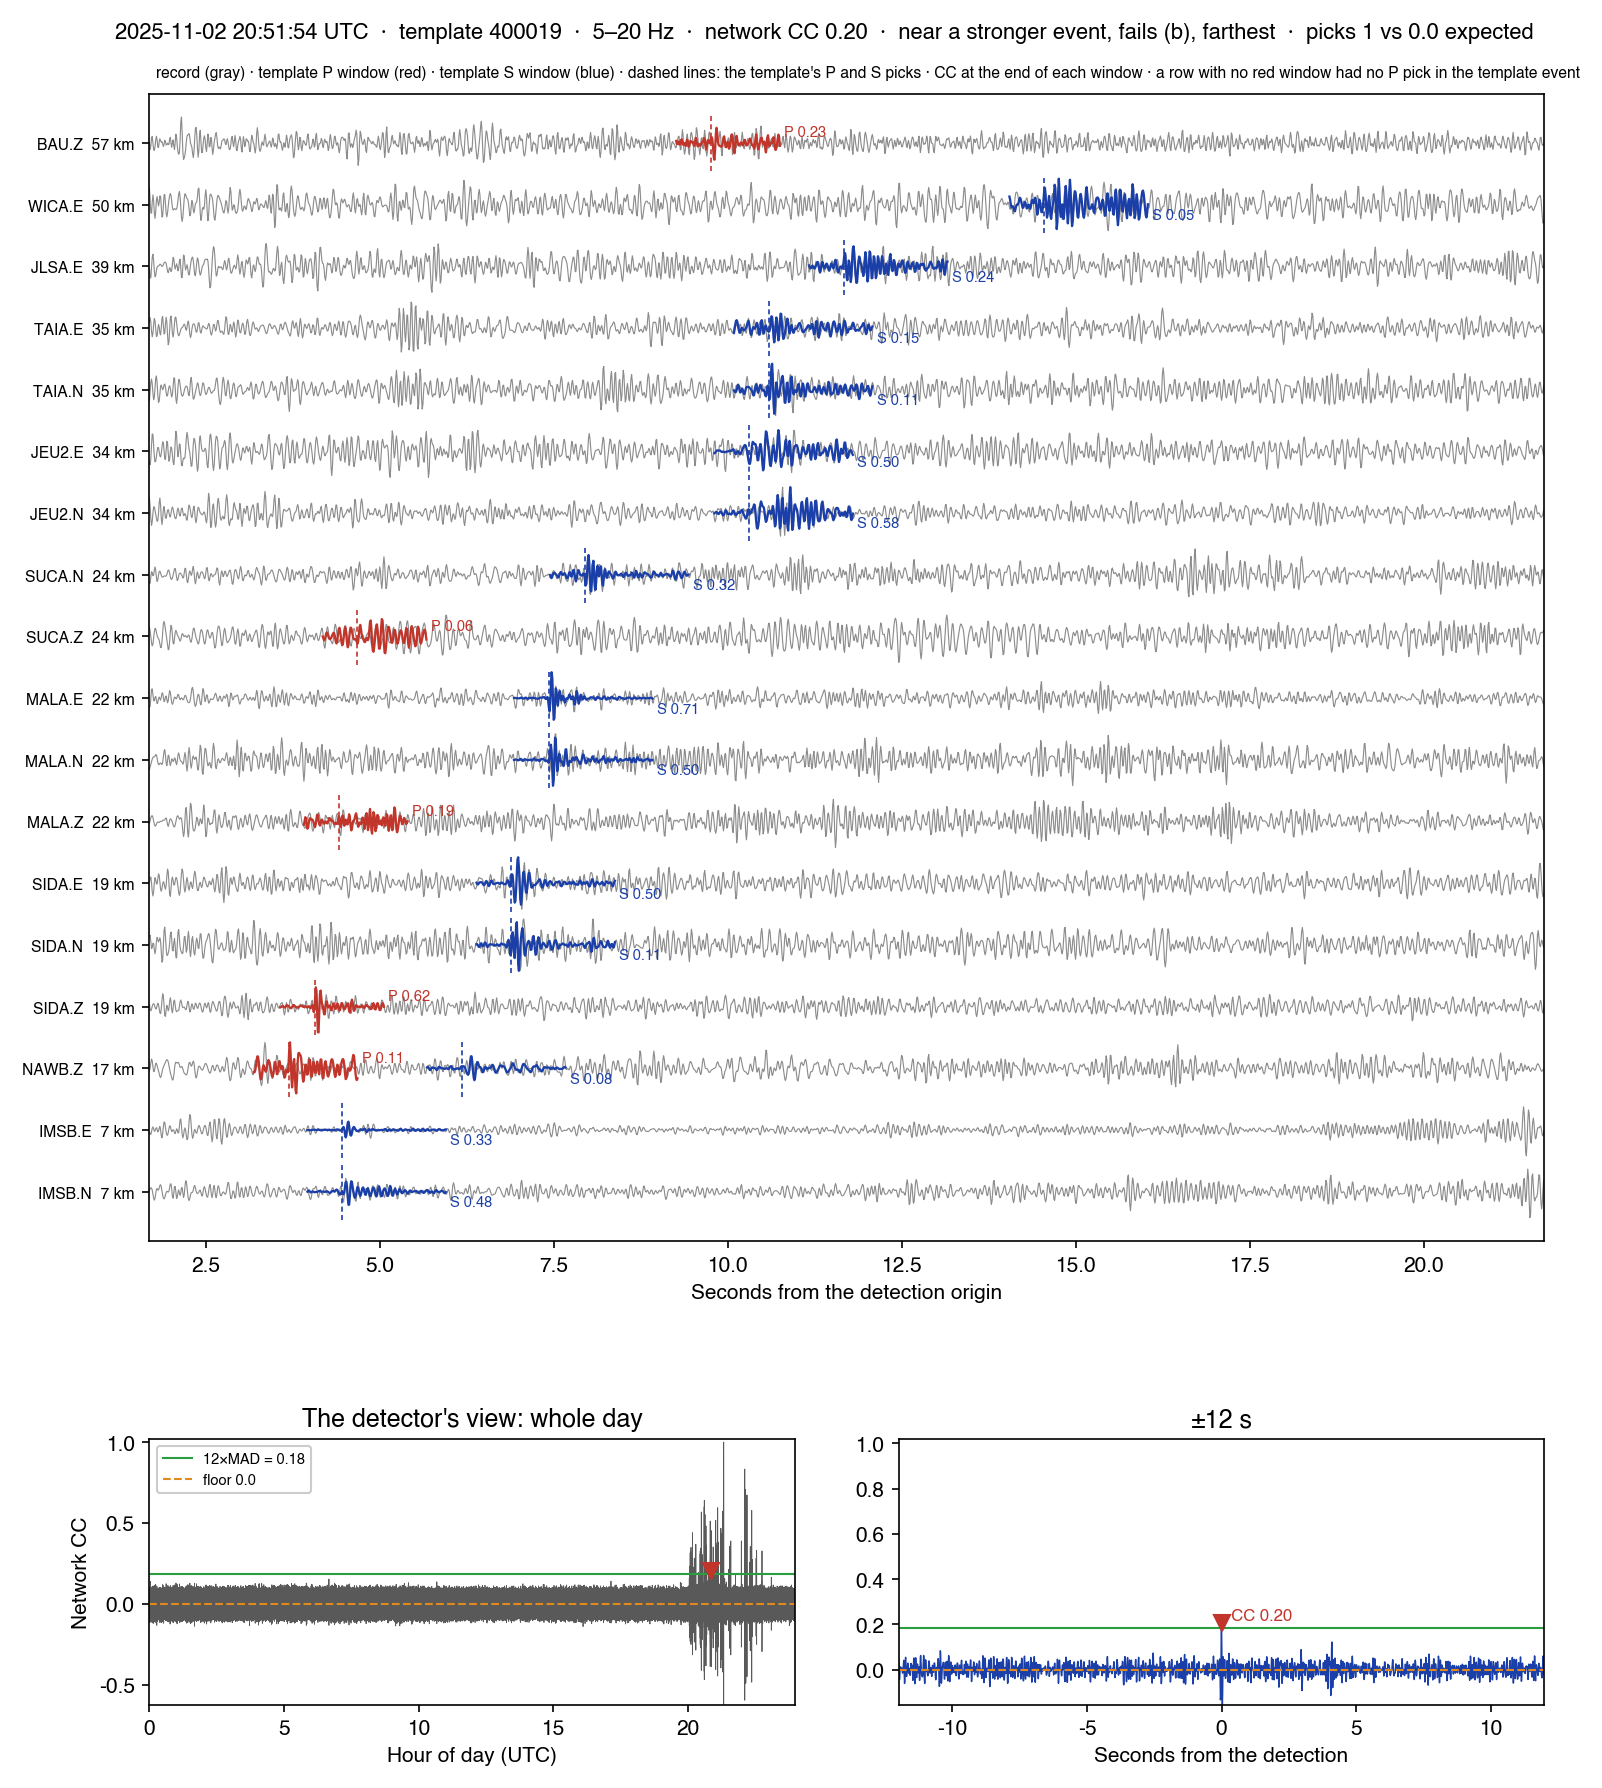

In [8]:
band = f'{C.BANDPASS[0]:g}–{C.BANDPASS[1]:g} Hz'
iso_fail = vet[~vet.near_stronger & ~vet.pass_b].sort_values('cc'); iso_pass = vet[~vet.near_stronger & vet.pass_a & vet.pass_b].sort_values('cc')
nf = vet[vet.near_stronger & ~vet.pass_b]; nf = nf.reindex(nf.dt_to_stronger_s.abs().sort_values().index)
picks_sets = [('isolated, fails (b), strongest', iso_fail.iloc[-1]), ('isolated, passes (a) and (b), weakest', iso_pass.iloc[0]),
              ('near a stronger event, fails (b), closest', nf.iloc[0]), ('near a stronger event, fails (b), farthest', nf.iloc[-1])]
for lab, r in picks_sets:
    det = pd.Timestamp(r.origin); c = int(r.template_cuspid); k = cusp.index(c); lat, lon = tpl_loc.loc[c, ['latitude', 'longitude']]; day = DAYS[det.dayofyear]
    ch, net, mean = S.detection_vs_template(sh, k, r.origin, present=day[1]); res = S.template_cc_day(sh, k, det.year, det.dayofyear, day=day)
    png = f'{FIG}/{det:%Y%m%d_%H%M%S}_{c}_set.png'
    S.plot_detection_set(sh, k, r.origin, ch, f'{det:%Y-%m-%d %H:%M:%S} UTC  ·  template {c}  ·  {band}  ·  network CC {net:.2f}  ·  {lab}  ·  picks {int(r.n_match)} vs {r.expected:.1f} expected',
                         png, res=res, tpl_lat=lat, tpl_lon=lon)
    display(Image(png))

## Comprehensive summary

In [9]:
summary = pd.DataFrame([
    ('New detections', len(vet)),
    ('Isolated / within 15 s of a stronger detection', f'{int((~vet.near_stronger).sum())} / {int(vet.near_stronger.sum())}'),
    ('(a) pass: isolated / near stronger', f'{int((vet.pass_a & ~vet.near_stronger).sum())} / {int((vet.pass_a & vet.near_stronger).sum())}'),
    ('(b) pass: isolated / near stronger', f'{int((vet.pass_b & ~vet.near_stronger).sum())} / {int((vet.pass_b & vet.near_stronger).sum())}'),
    ('(a) and (b) pass: isolated / near stronger', f'{int((vet.pass_a & vet.pass_b & ~vet.near_stronger).sum())} / {int((vet.pass_a & vet.pass_b & vet.near_stronger).sum())}'),
    ('(c) repeat-at-lag hits: observed vs jittered control (mean, 95th pct)', f'{len(obs)} vs {np.mean(shuf):.0f}, {np.percentile(shuf, 95):.0f}: excess {excess_c}'),
    ('Reference events: median picks above chance (positive control)', f'{B[B.kind == "reference"].excess.median():.1f}'),
], columns=['quantity', 'value'])
display(summary)
print('Evidence only; the vetting table is catalogs/fmf_new_detections_vetting.csv. Which detections go to relocation is decision D21 (user).')

,quantity,value
0,New detections,207
1,Isolated / within 15 s of a stronger detection,114 / 93
2,(a) pass: isolated / near stronger,113 / 91
3,(b) pass: isolated / near stronger,58 / 18
4,(a) and (b) pass: isolated / near stronger,58 / 18
5,(c) repeat-at-lag hits: observed vs jittered c...,"311 vs 321, 432: excess False"
6,Reference events: median picks above chance (p...,28.5


Evidence only; the vetting table is catalogs/fmf_new_detections_vetting.csv. Which detections go to relocation is decision D21 (user).
